In [4]:
import numpy as np 
import tensorflow as tf 
import matplotlib.pyplot as plt
import pandas as pd 
import os 
import seaborn as sns
from sklearn.model_selection import train_test_split
from  sklearn.metrics import accuracy_score, classification_report, confusion_matrix 
from sklearn.preprocessing import StandardScaler
SEED = 42 
np.random.seed(SEED)
tf.random.set_seed(SEED)


In [5]:
NUM_SAMPLES_PER_CLASS = 1500
SIGNAL_LENGTH = 128

CLASS_NAMES = [
    "OMA",
    "NOMA Low",
    "NOMA Medium",
    "NOMA High"
]

def generate_qpsk(n):
    bits = np.random.randint(0, 2, (n, 2))

    symbols = (
        (1 - 2 * bits[:, 0]) +
        1j * (1 - 2 * bits[:, 1])
    ) / np.sqrt(2)

    return symbols


def generate_signal(class_id):

    s1 = generate_qpsk(SIGNAL_LENGTH)
    s2 = generate_qpsk(SIGNAL_LENGTH)

    if class_id == 0:
        alpha = 0.0

    elif class_id == 1:
        alpha = 0.15

    elif class_id == 2:
        alpha = 0.35

    else:
        alpha = 0.50

    signal = (
        np.sqrt(1 - alpha) * s1 +
        np.sqrt(alpha) * s2
    )

    snr_db = np.random.uniform(15, 25)
    snr_linear = 10 ** (snr_db / 10)

    noise_power = 1 / snr_linear

    noise = np.sqrt(noise_power / 2) * (
        np.random.randn(SIGNAL_LENGTH) +
        1j * np.random.randn(SIGNAL_LENGTH)
    )

    received = signal + noise

    iq = np.stack(
        [received.real, received.imag],
        axis=-1
    )

    return iq.astype(np.float32)


X = []
y = []

for class_id in range(4):

    for _ in range(NUM_SAMPLES_PER_CLASS):

        X.append(generate_signal(class_id))
        y.append(class_id)

X = np.array(X)
y = np.array(y)

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)
print("Classes:", CLASS_NAMES)

Dataset shape: (6000, 128, 2)
Labels shape: (6000,)
Classes: ['OMA', 'NOMA Low', 'NOMA Medium', 'NOMA High']


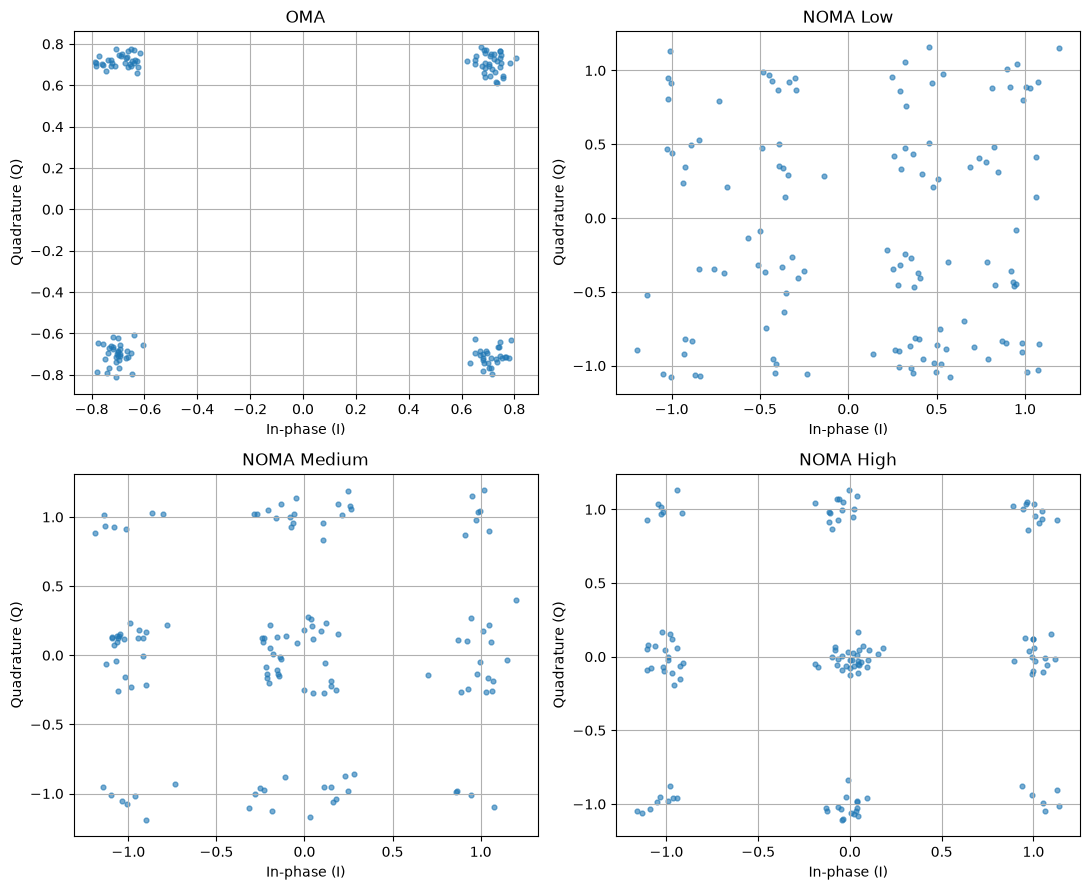

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for class_id, ax in enumerate(axes.flat):

    sample = X[y == class_id][0]

    ax.scatter(
        sample[:, 0],
        sample[:, 1],
        s=12,
        alpha=0.6
    )

    ax.set_title(CLASS_NAMES[class_id])
    ax.set_xlabel("In-phase (I)")
    ax.set_ylabel("Quadrature (Q)")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=SEED, stratify=y)
print("Training set shape:", X_train.shape, y_train.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (4800, 128, 2) (4800,)
Test set shape: (1200, 128, 2) (1200,)
